In [13]:
import os, numpy as np, networkx as nx

base="./result/wo_layer/stage1/tuning"
results=[]

def conv_score(v):
    v=np.asarray(v,float)
    v=v[np.isfinite(v)]
    if len(v)<2:return np.nan
    k=min(5,len(v)//2)
    s,e=np.mean(v[:k]),np.mean(v[-k:])
    return (s-e)/(abs(s)+1e-12)

for f in os.listdir(base):
    p=os.path.join(base,f)
    if not os.path.isdir(p):continue

    try:
        bs=int(f.split("_")[0].replace("bs",""))
        dp=float(f.split("_")[1].replace("dp",""))
        sw=float(f.split("_")[2].replace("sw",""))
    except:
        continue

    gp=os.path.join(p,"dynamic_full_graphs.npy")
    if not os.path.exists(gp):continue

    data=np.load(gp,allow_pickle=True)
    mats=[]; cents=[]

    for g in data:
        if isinstance(g,np.ndarray): A=g.copy()
        elif isinstance(g,(nx.Graph,nx.DiGraph)): A=nx.to_numpy_array(g)
        elif isinstance(g,dict) and "adj" in g: A=g["adj"].copy()
        else: continue

        mats.append(A)
        B=A.copy(); np.fill_diagonal(B,0)
        N=B.shape[0]
        cents.append(np.mean(np.sum(B,axis=1))/(N-1) if N>1 else 0)

    if not mats:continue

    mean_graph=np.mean(mats,axis=0)
    mean_centrality=np.mean(cents)

    npos=np.sum(mean_graph>0)
    nneg=np.sum(mean_graph<0)
    ratio=np.inf if nneg==0 else npos/nneg

    tp=os.path.join(p,"train_losses.npy")
    num_epochs=len(np.load(tp,allow_pickle=True)) if os.path.exists(tp) else np.nan

    vp=os.path.join(p,"val_losses.npy")
    if os.path.exists(vp):
        val=np.asarray(np.load(vp,allow_pickle=True),float)
        best_val=np.nanmin(val) if len(val) else np.nan
        conv=conv_score(val)
    else:
        best_val=conv=np.nan

    results.append([
        bs,dp,sw,
        mean_centrality,
        num_epochs,
        ratio,
        mean_graph,
        best_val,
        conv
    ])

results=np.array(results,dtype=object)

print(f"Calculated {len(results)} parameter combinations.")
print("[bs, dp, sw, mean_centrality, num_epochs, "
      "pos_neg_ratio, mean_graph, best_val_loss, convergence_score]")

Calculated 64 parameter combinations.
[bs, dp, sw, mean_centrality, num_epochs, pos_neg_ratio, mean_graph, best_val_loss, convergence_score]


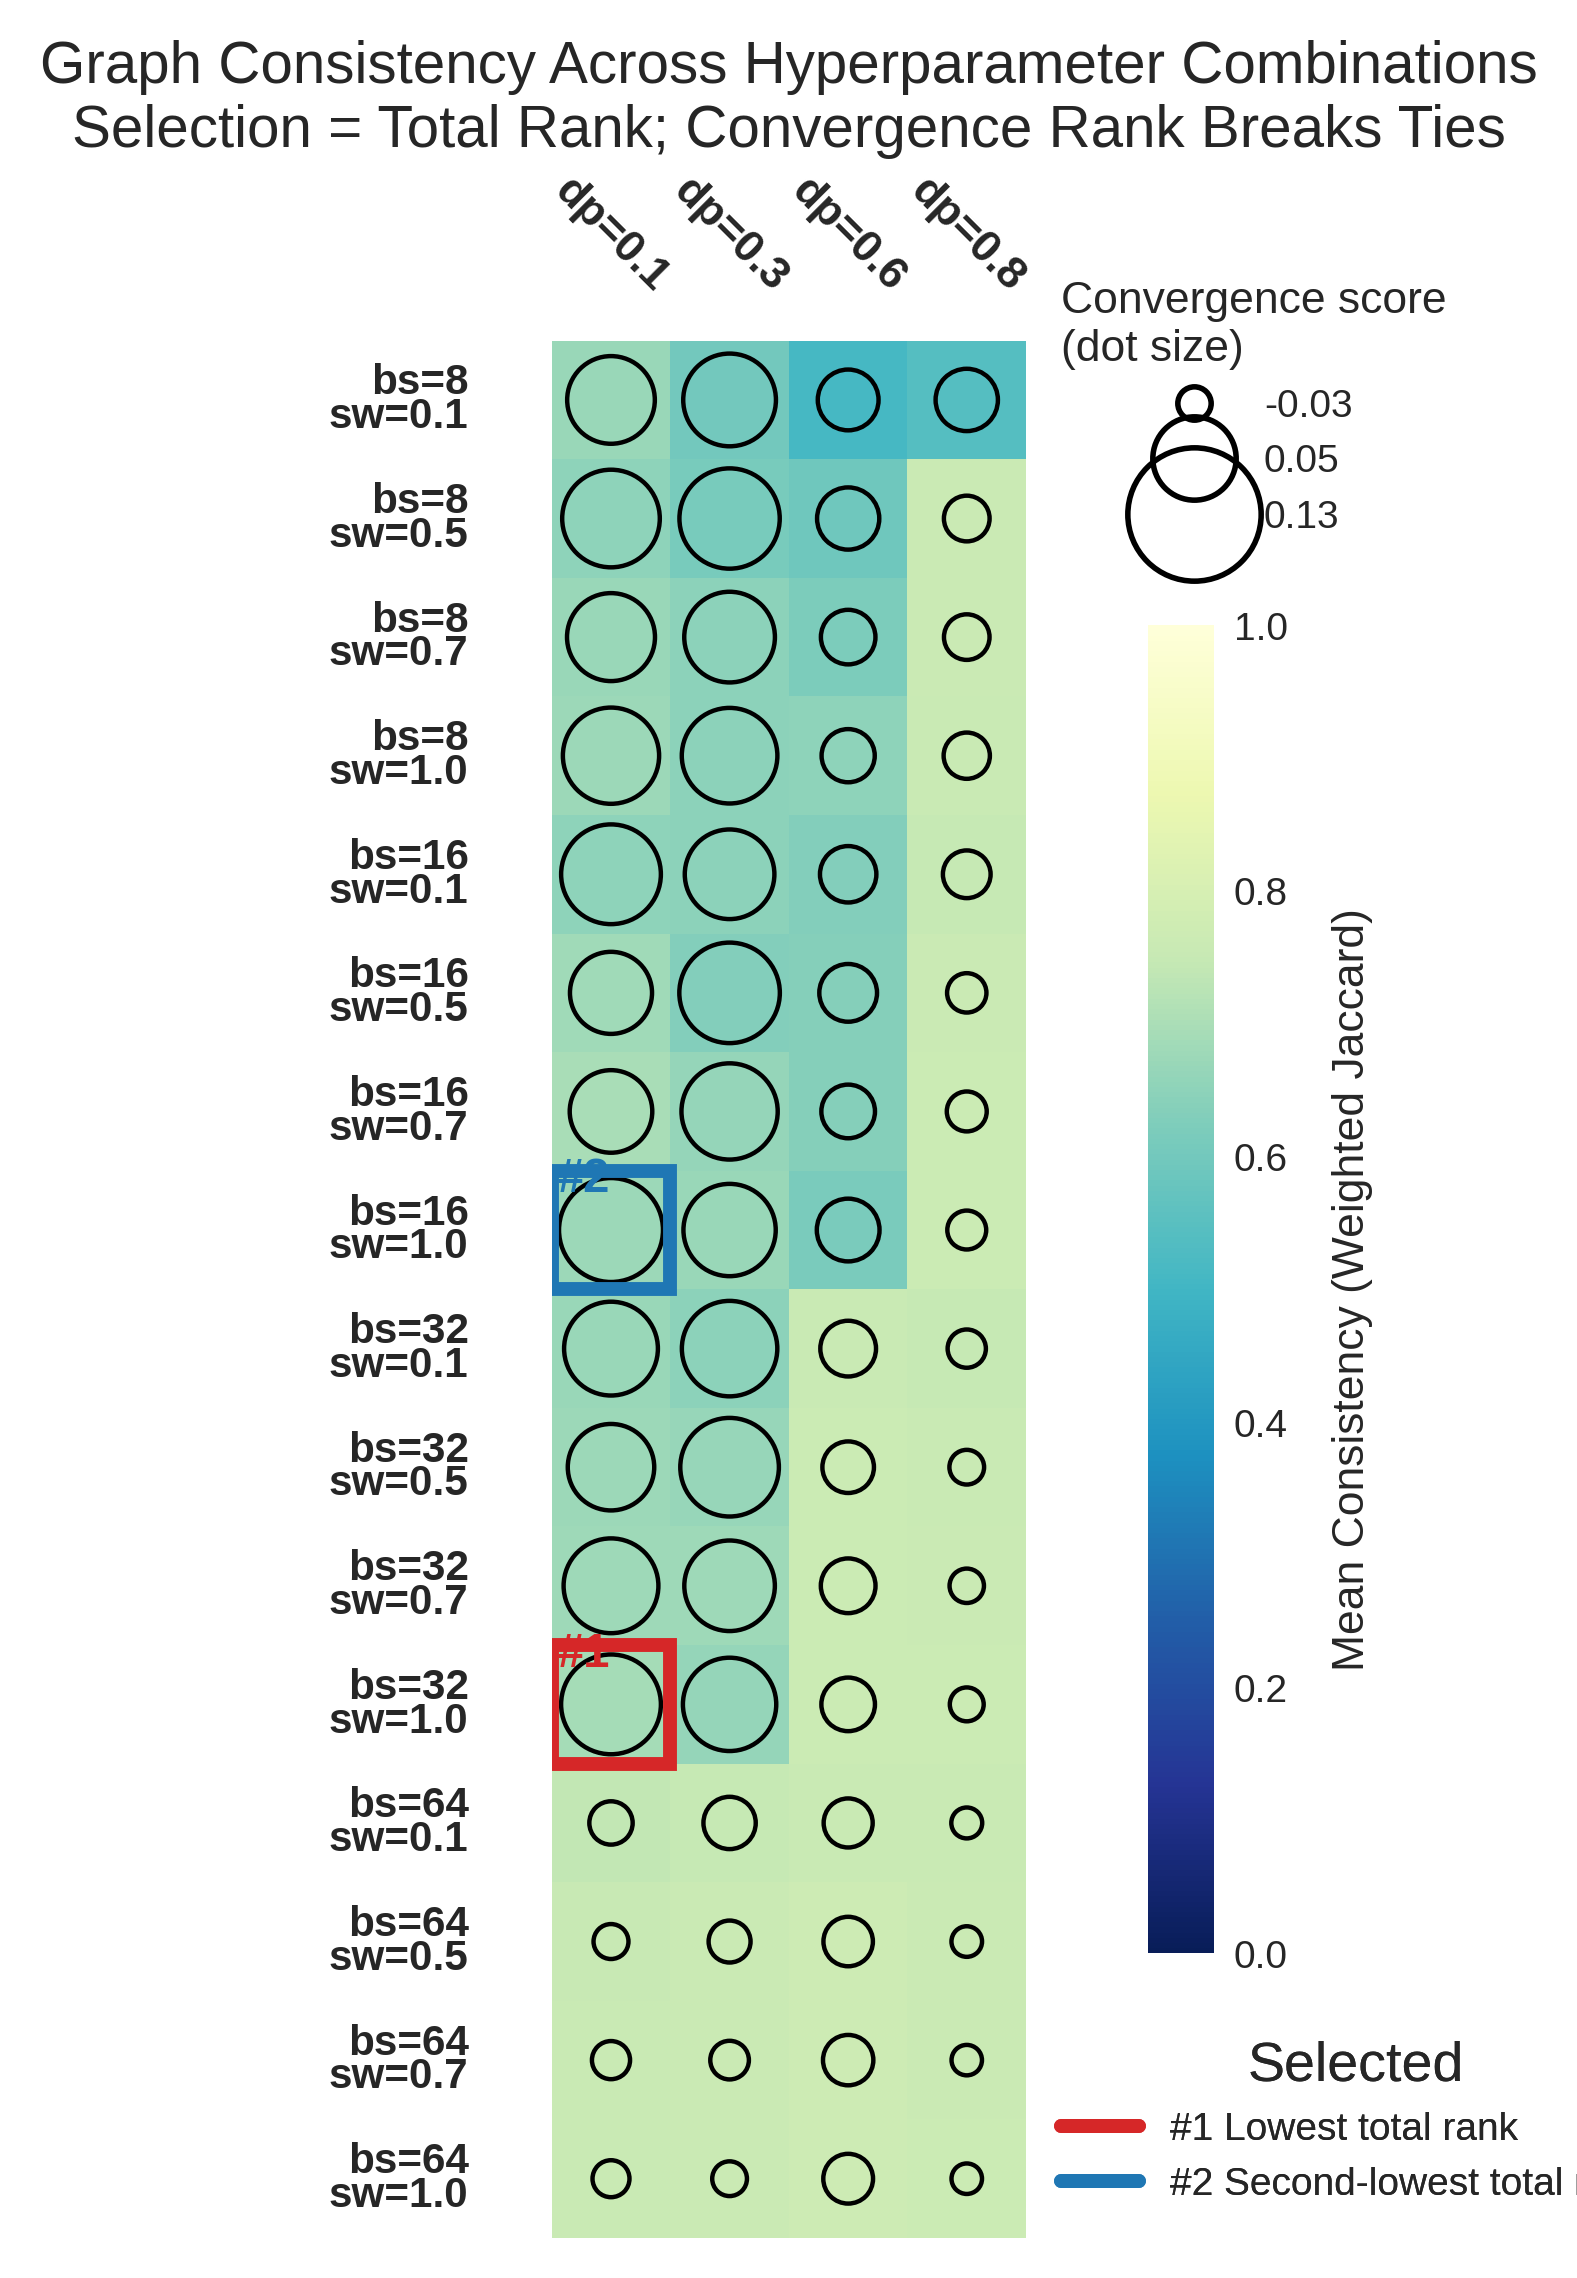

#1: bs=32, dp=0.1, sw=1.0 | conv=0.118(r=4) | cons=0.6877(r=4) | total=8
#2: bs=16, dp=0.1, sw=1.0 | conv=0.132(r=1) | cons=0.6754(r=10) | total=11
#3: bs=8, dp=0.1, sw=1.0 | conv=0.106(r=9) | cons=0.6754(r=9) | total=18
#4: bs=32, dp=0.1, sw=0.7 | conv=0.102(r=12) | cons=0.6790(r=7) | total=19
#5: bs=32, dp=0.3, sw=0.5 | conv=0.114(r=6) | cons=0.6643(r=15) | total=21
#6: bs=16, dp=0.1, sw=0.1 | conv=0.118(r=5) | cons=0.6502(r=18) | total=23
#7: bs=16, dp=0.3, sw=0.7 | conv=0.106(r=8) | cons=0.6626(r=16) | total=24
#8: bs=32, dp=0.3, sw=0.7 | conv=0.089(r=18) | cons=0.6795(r=6) | total=24
#9: bs=32, dp=0.1, sw=0.1 | conv=0.099(r=13) | cons=0.6704(r=12) | total=25
#10: bs=8, dp=0.1, sw=0.5 | conv=0.111(r=7) | cons=0.6493(r=19) | total=26


In [14]:
import os,numpy as np,matplotlib.pyplot as plt,seaborn as sns
from matplotlib.lines import Line2D
import matplotlib.patches as patches
from scipy.stats import rankdata

R=np.array(results,dtype=object)
BS,DP,SW=[8,16,32,64],[.1,.3,.6,.8],[.1,.5,.7,1.]
base="./result/wo_layer/stage1/tuning"

# order
O=[]
for bs in BS:
    for sw in SW:
        for dp in DP:
            x=R[(R[:,0]==bs)&(R[:,1]==dp)&(R[:,2]==sw)]
            if len(x):O.append(x[0])
O=np.array(O,dtype=object);G=O[:,6]

# weighted Jaccard
def wj(A,B,t=.01):
    A,B=np.nan_to_num(A).copy(),np.nan_to_num(B).copy()
    Ap,Bp=np.where(A>t,A,0),np.where(B>t,B,0)
    An,Bn=np.where(A<-t,-A,0),np.where(B<-t,-B,0)
    dp,dn=np.maximum(Ap,Bp).sum(),np.maximum(An,Bn).sum()
    jp=np.minimum(Ap,Bp).sum()/dp if dp else 0
    jn=np.minimum(An,Bn).sum()/dn if dn else 0
    return (jp+jn)/2

n=len(G);S=np.eye(n)
for i in range(n):
    for j in range(i+1,n):S[i,j]=S[j,i]=wj(G[i],G[j])

Hmean=np.array([np.delete(S[i],i).mean() for i in range(n)]).reshape(len(BS)*len(SW),len(DP))

# convergence score
def cs(v):
    v=np.asarray(v,float);v=v[np.isfinite(v)]
    if len(v)<2:return np.nan
    s=v[:min(5,len(v))].mean()
    y=v/(abs(s)+1e-12)
    return 1-np.trapz(y,dx=1)/(len(y)-1)

scores=[]
for r in O:
    bs,dp,sw=int(r[0]),float(r[1]),float(r[2])
    p=os.path.join(base,f"bs{bs}_dp{dp}_sw{sw}","val_losses.npy")
    scores.append(cs(np.load(p,allow_pickle=True)) if os.path.exists(p) else np.nan)

Hconv=np.array(scores).reshape(Hmean.shape)

# ranking: convergence > 0
conv,cons=Hconv.ravel(),Hmean.ravel()
valid=np.isfinite(conv)&np.isfinite(cons)&(conv>0)

rc=np.full(len(conv),np.inf);rs=np.full(len(cons),np.inf)
rc[valid]=rankdata(-conv[valid],method="average")
rs[valid]=rankdata(-cons[valid],method="average")

total=rc+rs
eligible=np.where(valid)[0]

# primary: lower total rank
# tie-breaker: lower convergence rank
order=eligible[np.lexsort((rc[eligible],total[eligible]))]
top1,top2=order[:2]

# sizes
vmin,vmax=np.nanmin(Hconv),np.nanmax(Hconv)
sizes=30+(Hconv-vmin)/(vmax-vmin+1e-9)*320

# plot
plt.style.use("seaborn-v0_8-white")
fig,ax=plt.subplots(figsize=(8.6,6.3),dpi=400)

sns.heatmap(Hmean,cmap="YlGnBu_r",vmin=0,vmax=1,square=True,ax=ax,
            cbar_kws={"label":"Mean Consistency (Weighted Jaccard)","shrink":.7,"pad":.04})

cbar=ax.collections[0].colorbar
cbar.ax.tick_params(labelsize=7)
cbar.set_label("Mean Consistency (Weighted Jaccard)",fontsize=8,labelpad=8)

for i in range(Hconv.shape[0]):
    for j in range(Hconv.shape[1]):
        if np.isfinite(Hconv[i,j]):
            ax.scatter(j+.5,i+.5,s=sizes[i,j],facecolors="none",edgecolors="k",lw=.8)

for g,bs in enumerate(BS):
    for k,sw in enumerate(SW):
        i=g*len(SW)+k
        ax.text(-.7,i+.5,f"bs={bs}\nsw={sw:.1f}",
                ha="right",va="center",fontsize=7.6,weight="bold",linespacing=.8)

for j,dp in enumerate(DP):
    ax.text(j+.5,-.35,f"dp={dp:.1f}",
            ha="center",va="bottom",fontsize=8,weight="bold",rotation=-45)

# size legend
levels=np.linspace(vmin,vmax,3)
h=[Line2D([],[],marker="o",ls="None",mfc="none",mec="k",mew=1,
          markersize=6+18*(v-vmin)/(vmax-vmin+1e-9),label=f"{v:.2f}") for v in levels]

L1=ax.legend(handles=h,title="Convergence score\n(dot size)",
             loc="upper left",bbox_to_anchor=(1,1.05),
             fontsize=7,title_fontsize=8,frameon=False)
ax.add_artist(L1)

# highlights
colors=["#D62728","#1F77B4"]
for rank,x in enumerate([top1,top2],1):
    i,j=divmod(x,Hmean.shape[1])
    ax.add_patch(patches.Rectangle((j,i),1,1,fill=False,
                                   edgecolor=colors[rank-1],lw=2.5))
    ax.text(j+.05,i+.18,f"#{rank}",color=colors[rank-1],
            fontsize=8.5,fontweight="bold")

L2=ax.legend(
    handles=[
        Line2D([],[],color=colors[0],lw=2.5,label="#1 Lowest total rank"),
        Line2D([],[],color=colors[1],lw=2.5,label="#2 Second-lowest total rank")
    ],
    loc="lower left",bbox_to_anchor=(1,0),
    fontsize=7,frameon=False,title="Selected"
)
ax.add_artist(L2)

ax.set_title("Graph Consistency Across Hyperparameter Combinations\n"
             "Selection = Total Rank; Convergence Rank Breaks Ties",
             fontsize=10.5,pad=35)

ax.set_xlabel("");ax.set_ylabel("")
ax.set_xticks([]);ax.set_yticks([])

plt.tight_layout(rect=[0,0,.92,.92])
plt.savefig("consistency_mean_wo_layer_stage1.png",
            dpi=600,bbox_inches="tight",transparent=True)
plt.show()

# ranking
for rank,x in enumerate(order[:10],1):
    i,j=divmod(x,len(DP))
    bs,sw,dp=BS[i//len(SW)],SW[i%len(SW)],DP[j]
    print(f"#{rank}: bs={bs}, dp={dp}, sw={sw} | "
          f"conv={Hconv[i,j]:.3f}(r={rc[x]:.0f}) | "
          f"cons={Hmean[i,j]:.4f}(r={rs[x]:.0f}) | total={total[x]:.0f}")